# TP — Les bases de PyTorch
Correction des quatre exercices : régression, Iris, MLP MNIST et CNN MNIST.

Installation si nécessaire : `pip install torch torchvision scikit-learn matplotlib`. MNIST nécessite un accès Internet au premier téléchargement.

In [6]:
import torch
from torch import nn
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, precision_score, recall_score, f1_score
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

torch.set_num_threads(2)
torch.manual_seed(42)
Path('captures').mkdir(exist_ok=True)
Path('models').mkdir(exist_ok=True)

def afficher(nom):
    plt.tight_layout()
    plt.savefig(f'captures/{nom}.png', dpi=150, bbox_inches='tight')
    plt.show()

def courbe(losses, nom):
    plt.figure(figsize=(6, 3))
    plt.plot(range(1, len(losses)+1), losses)
    plt.xlabel('Époque'); plt.ylabel('Perte'); plt.grid(alpha=.3)
    afficher(nom)

def confusion(y, pred, noms, fichier):
    ConfusionMatrixDisplay.from_predictions(y, pred, display_labels=noms, cmap='Blues')
    afficher(fichier)

## Exercice 1 — Régression du salaire
On génère 300 salariés fictifs selon la formule du sujet, avec un bruit aléatoire de 500 DH.

In [7]:
import torch
from torch import nn
import matplotlib.pyplot as plt

torch.manual_seed(42)

# Nombre de salariés
n = 300

# Ancienneté : de 0 à 20 ans
anciennete = torch.randint(0, 21, (n, 1)).float()

# Expertise : de 1 à 5
expertise = torch.randint(1, 6, (n, 1)).float()

# Variations aléatoires des salaires
bruit = torch.randn(n, 1) * 500

# Salaire mensuel en DH
salaires = (
    4000
    + 600 * anciennete
    + 1500 * expertise
    + bruit
)

# Matrice des entrées : dimensions (300, 2)
X = torch.cat([anciennete, expertise], dim=1)

# Sortie : dimensions (300, 1)
y = salaires

for i in range(5):
    print(
        f"Ancienneté : {X[i, 0].item():.0f} ans | "
        f"Expertise : {X[i, 1].item():.0f}/5 | "
        f"Salaire : {y[i, 0].item():.2f} DH"
    )

Ancienneté : 15 ans | Expertise : 2/5 | Salaire : 16262.90 DH
Ancienneté : 2 ans | Expertise : 3/5 | Salaire : 10541.39 DH
Ancienneté : 4 ans | Expertise : 3/5 | Salaire : 10948.37 DH
Ancienneté : 19 ans | Expertise : 3/5 | Salaire : 20028.54 DH
Ancienneté : 18 ans | Expertise : 2/5 | Salaire : 18036.38 DH


Dimensions X et y : torch.Size([300, 2]) torch.Size([300, 1])
Salaire moyen : 15010.55 DH


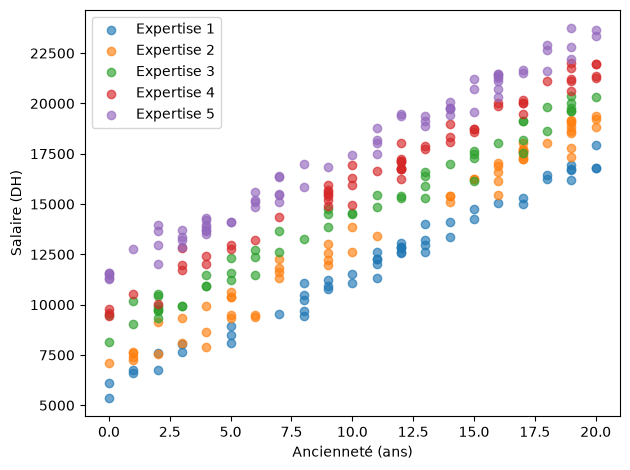

In [8]:
print('Dimensions X et y :', X.shape, y.shape)
print(f'Salaire moyen : {y.mean():.2f} DH')
for niveau in range(1, 6):
    mask = X[:, 1] == niveau
    plt.scatter(X[mask, 0], y[mask, 0], label=f'Expertise {niveau}', alpha=.65)
plt.xlabel('Ancienneté (ans)'); plt.ylabel('Salaire (DH)'); plt.legend()
afficher('01_salaires')

### Préparation et entraînement
La séparation 80/20 permet de tester sur des données non vues. On standardise les entrées avec les statistiques du train uniquement et on divise les salaires par 1 000.

In [9]:
indices = torch.randperm(n)
limite = int(0.8 * n)

train_indices = indices[:limite]
test_indices = indices[limite:]

X_train = X[train_indices]
X_test = X[test_indices]

y_train = y[train_indices] / 1000
y_test = y[test_indices] / 1000

# Statistiques calculées uniquement sur le jeu d'entraînement
moyenne = X_train.mean(dim=0, keepdim=True)
ecart_type = X_train.std(dim=0, keepdim=True)

X_train_norm = (X_train - moyenne) / ecart_type
X_test_norm = (X_test - moyenne) / ecart_type

Époque 100 | Perte : 0.2391
Époque 200 | Perte : 0.2391
Époque 300 | Perte : 0.2391
Époque 400 | Perte : 0.2391
Époque 500 | Perte : 0.2391


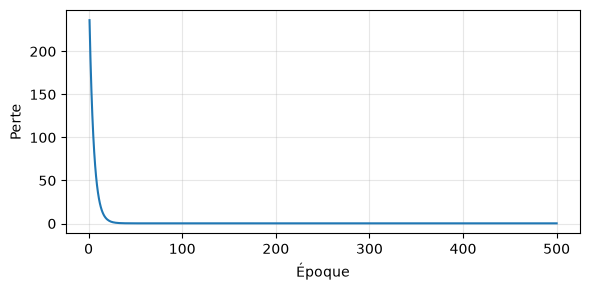

In [10]:
model = nn.Linear(2, 1)
criterion = nn.MSELoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.05)
historique = []
model.train()
for epoch in range(500):
    optimizer.zero_grad()
    predictions = model(X_train_norm)
    loss = criterion(predictions, y_train)
    loss.backward()
    optimizer.step()
    historique.append(loss.item())
    if (epoch+1) % 100 == 0:
        print(f'Époque {epoch+1} | Perte : {loss.item():.4f}')
courbe(historique, '02_perte_regression')

MAE : 381.64 DH
Salaire estimé : 14201.94 DH (théorique : 14200 DH)
Coefficients : ancienneté=592.66, expertise=1490.75, biais=4090.30


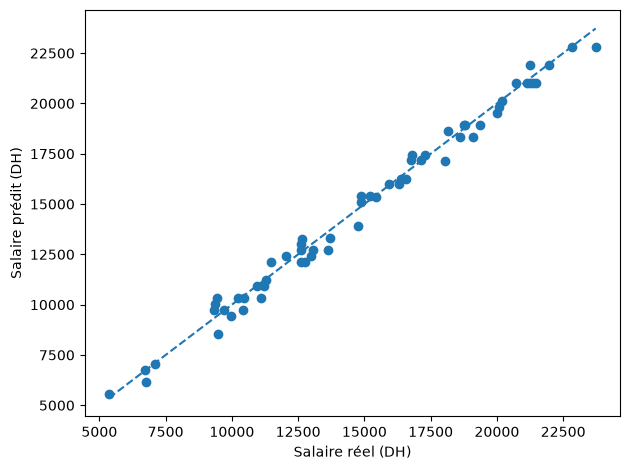

In [11]:
model.eval()
with torch.no_grad():
    predictions_dh = model(X_test_norm) * 1000
    salaires_reels_dh = y_test * 1000
    mae = (predictions_dh - salaires_reels_dh).abs().mean()
    nouveau_salarie = torch.tensor([[7., 4.]])
    salaire_predit = model((nouveau_salarie - moyenne) / ecart_type) * 1000
    poids = model.weight / ecart_type * 1000
    biais = model.bias * 1000 - (poids * moyenne).sum()
print(f'MAE : {mae.item():.2f} DH')
print(f'Salaire estimé : {salaire_predit.item():.2f} DH (théorique : 14200 DH)')
print(f'Coefficients : ancienneté={poids[0,0]:.2f}, expertise={poids[0,1]:.2f}, biais={biais.item():.2f}')
plt.scatter(salaires_reels_dh, predictions_dh)
lo, hi = salaires_reels_dh.min().item(), salaires_reels_dh.max().item()
plt.plot([lo,hi],[lo,hi], '--'); plt.xlabel('Salaire réel (DH)'); plt.ylabel('Salaire prédit (DH)')
afficher('03_predictions')

**Réponses :** une année supplémentaire augmente le salaire théorique de 600 DH à expertise constante. Le bruit empêche une perte nulle. À 40 ans, le modèle extrapole hors des données et sa fiabilité est inconnue. Plus de bruit augmente généralement les erreurs. Les coefficients sont convertis en DH par division par les écarts-types et multiplication par 1 000 ; le biais est corrigé du centrage. Le niveau d’expertise est supposé avoir un effet linéaire.

## Exercice 2 — Classification Iris
Les quatre mesures sont les longueurs et largeurs du sépale et du pétale. Les labels sont des entiers `torch.long` nécessaires à CrossEntropyLoss. Le scaler est ajusté sur le train pour éviter la fuite de données.

In [12]:
import torch
from torch import nn
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

torch.manual_seed(42)

# Charger les données
iris = load_iris()
X, y = iris.data, iris.target

# Séparer les données : 80 % entraînement, 20 % test
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Ajuster la normalisation uniquement sur l'entraînement
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Convertir en tenseurs
X_train = torch.tensor(X_train, dtype=torch.float32)
X_test = torch.tensor(X_test, dtype=torch.float32)
y_train = torch.tensor(y_train, dtype=torch.long)
y_test = torch.tensor(y_test, dtype=torch.long)

print("Dimensions :", X_train.shape, y_train.shape)

Dimensions : torch.Size([120, 4]) torch.Size([120])


Accuracy réseau : 100.0%


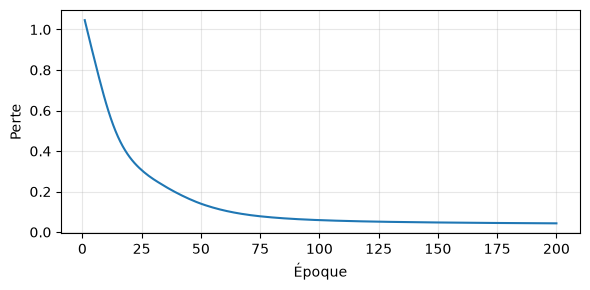

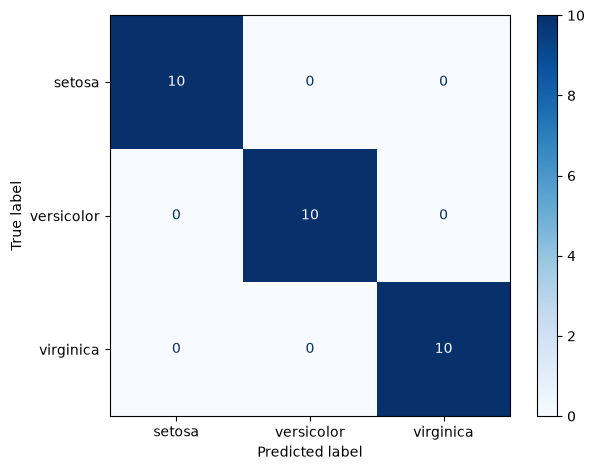

In [13]:
def entrainer_iris(model):
    optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
    criterion = nn.CrossEntropyLoss()
    losses = []
    model.train()
    for epoch in range(200):
        optimizer.zero_grad()
        logits = model(X_train)
        loss = criterion(logits, y_train)
        loss.backward()
        optimizer.step()
        losses.append(loss.item())
    model.eval()
    with torch.no_grad():
        pred = model(X_test).argmax(dim=1)
    return losses, pred, (pred == y_test).float().mean().item()

model_iris = nn.Sequential(nn.Linear(4, 16), nn.ReLU(), nn.Linear(16, 3))
losses, pred, acc = entrainer_iris(model_iris)
print(f'Accuracy réseau : {acc:.1%}')
courbe(losses, '04_perte_iris')
confusion(y_test, pred, iris.target_names, '05_confusion_iris')

Accuracy sans couche cachée : 90.0%


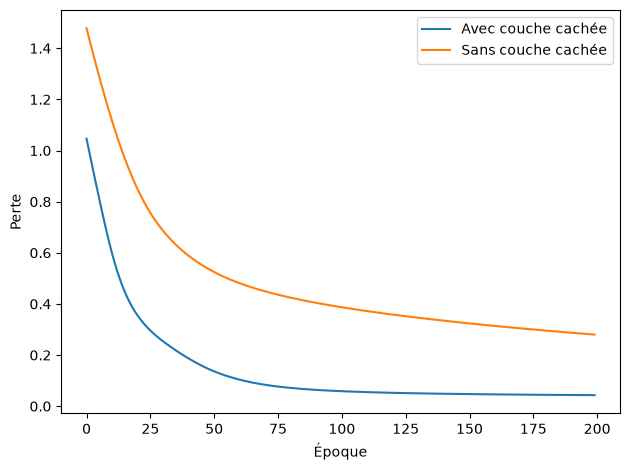

Espèce prédite : setosa


In [14]:
linear = nn.Linear(4, 3)
losses_linear, pred_linear, acc_linear = entrainer_iris(linear)
print(f'Accuracy sans couche cachée : {acc_linear:.1%}')
plt.plot(losses, label='Avec couche cachée'); plt.plot(losses_linear, label='Sans couche cachée')
plt.xlabel('Époque'); plt.ylabel('Perte'); plt.legend(); afficher('06_comparaison_iris')
import numpy as np
fleur = torch.tensor(scaler.transform([[5.1, 3.5, 1.4, 0.2]]), dtype=torch.float32)
with torch.no_grad():
    classe = model_iris(fleur).argmax(dim=1).item()
print('Espèce prédite :', iris.target_names[classe])

## Exercice 3 — MLP MNIST
Les images 28 × 28 sont aplaties en 784 valeurs. Le réseau contient 128 neurones cachés et 10 sorties. Les données sont chargées par mini-lots de 64. Pas de Softmax : CrossEntropyLoss reçoit les logits.

In [16]:
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Appareil :', device)

def chargeurs(transform):
    train = datasets.MNIST('./data', train=True, download=True, transform=transform)
    test = datasets.MNIST('./data', train=False, download=True, transform=transform)
    return DataLoader(train, batch_size=64, shuffle=True), DataLoader(test, batch_size=256, shuffle=False)

def entrainer(model, loader, epochs):
    model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
    history = []
    for epoch in range(epochs):
        model.train()
        total = 0.
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            total += loss.item() * labels.size(0)
        history.append(total / len(loader.dataset))
        print(f'Époque {epoch+1}/{epochs} | Perte : {history[-1]:.4f}')
    return history

def evaluer(model, loader):
    model.eval()
    vrais, predits, erreurs = [], [], []
    with torch.no_grad():
        for images, labels in loader:
            outputs = model(images.to(device))
            predicted_classes = outputs.argmax(dim=1).cpu()
            vrais.extend(labels.tolist()); predits.extend(predicted_classes.tolist())
            for i in (predicted_classes != labels).nonzero().flatten().tolist():
                if len(erreurs) < 10:
                    erreurs.append((images[i].clone(), labels[i].item(), predicted_classes[i].item()))
    scores = {'Accuracy': accuracy_score(vrais, predits), 'Precision': precision_score(vrais, predits, average='macro', zero_division=0), 'Recall': recall_score(vrais, predits, average='macro', zero_division=0), 'F1': f1_score(vrais, predits, average='macro', zero_division=0)}
    for nom, score in scores.items(): print(f'{nom} : {score:.2%}')
    return vrais, predits, erreurs, scores

def afficher_erreurs(erreurs, nom, normalise=False):
    fig, axes = plt.subplots(2, 5, figsize=(10, 4))
    for ax in axes.flat: ax.axis('off')
    for ax, (img, vrai, pred) in zip(axes.flat, erreurs):
        if normalise: img = img * 0.3081 + 0.1307
        ax.imshow(img.squeeze(), cmap='gray', vmin=0, vmax=1)
        ax.set_title(f'Vrai : {vrai} / Prédit : {pred}')
    afficher(nom)

def creer_mlp():
    return nn.Sequential(nn.Flatten(), nn.Linear(784,128), nn.ReLU(), nn.Linear(128,10))

Appareil : cpu


100.0%
100.0%
100.0%
100.0%


Époque 1/5 | Perte : 0.3542
Époque 2/5 | Perte : 0.1669
Époque 3/5 | Perte : 0.1165
Époque 4/5 | Perte : 0.0887
Époque 5/5 | Perte : 0.0698


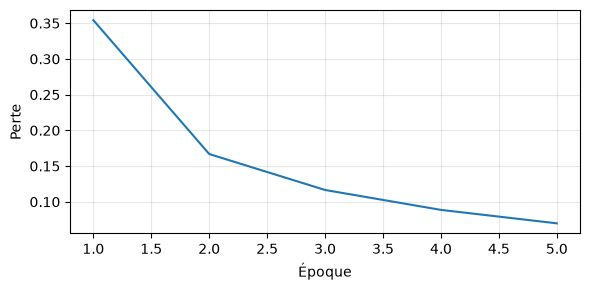

Accuracy : 97.55%
Precision : 97.53%
Recall : 97.53%
F1 : 97.53%


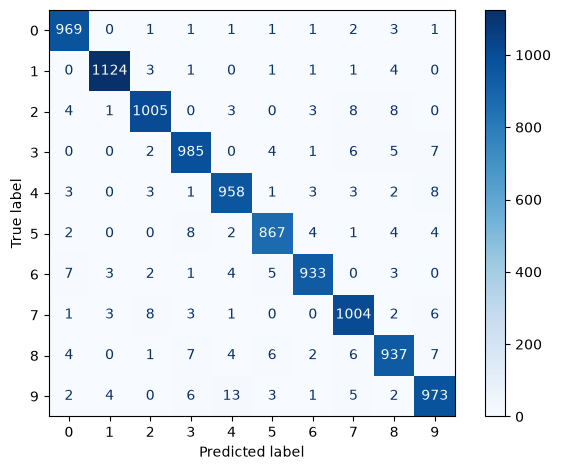

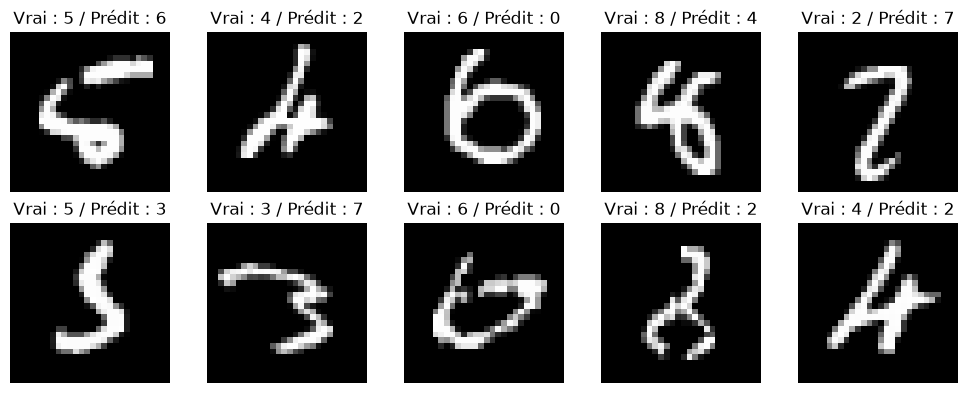

In [17]:
train_loader, test_loader = chargeurs(transforms.ToTensor())
mlp = creer_mlp().to(device)
mlp_losses = entrainer(mlp, train_loader, 5)
courbe(mlp_losses, '07_perte_mlp')
vrais, predits, erreurs, scores_mlp = evaluer(mlp, test_loader)
confusion(vrais, predits, list(range(10)), '08_confusion_mlp')
afficher_erreurs(erreurs, '09_erreurs_mlp')

In [18]:
torch.save(mlp.state_dict(), 'models/mnist_mlp.pth')
mlp_recharge = creer_mlp().to(device)
mlp_recharge.load_state_dict(torch.load('models/mnist_mlp.pth', map_location=device, weights_only=True))
mlp_recharge.eval()
images, labels = next(iter(test_loader))
with torch.no_grad():
    print('Prédictions identiques :', torch.equal(mlp(images.to(device)).argmax(1), mlp_recharge(images.to(device)).argmax(1)))

Prédictions identiques : True


## Exercice 4 — CNN MNIST
Le tenseur [64, 1, 28, 28] contient 64 images, un canal gris, 28 lignes et 28 colonnes. `shuffle=True` mélange les exemples à chaque époque. La normalisation utilise la moyenne et l’écart-type de MNIST.

Images : torch.Size([64, 1, 28, 28]) | Labels : torch.Size([64])


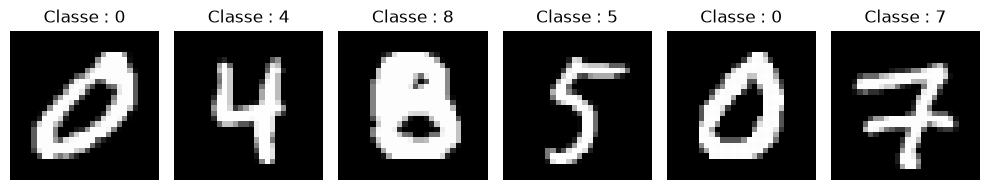

In [19]:
transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.1307,), (0.3081,))])
train_cnn, test_cnn = chargeurs(transform)
images, labels = next(iter(train_cnn))
print('Images :', images.shape, '| Labels :', labels.shape)
fig, axes = plt.subplots(1, 6, figsize=(10, 2))
for i, ax in enumerate(axes):
    ax.imshow(images[i,0] * 0.3081 + 0.1307, cmap='gray', vmin=0, vmax=1)
    ax.set_title(f'Classe : {labels[i].item()}'); ax.axis('off')
afficher('10_images_mnist')

Deux convolutions (16 puis 32 filtres) gardent la taille spatiale grâce au padding. Les deux max-poolings divisent la taille par deux : 28 → 14 → 7. La couche linéaire reçoit donc 32 × 7 × 7 = 1568 valeurs. Dropout désactive aléatoirement certains neurones pendant l’entraînement afin de limiter le surapprentissage.

Sortie : torch.Size([64, 10])
Époque 1/3 | Perte : 0.1846
Époque 2/3 | Perte : 0.0587
Époque 3/3 | Perte : 0.0437


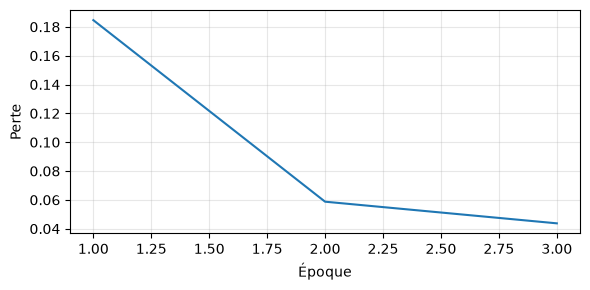

Accuracy : 98.69%
Precision : 98.68%
Recall : 98.68%
F1 : 98.68%


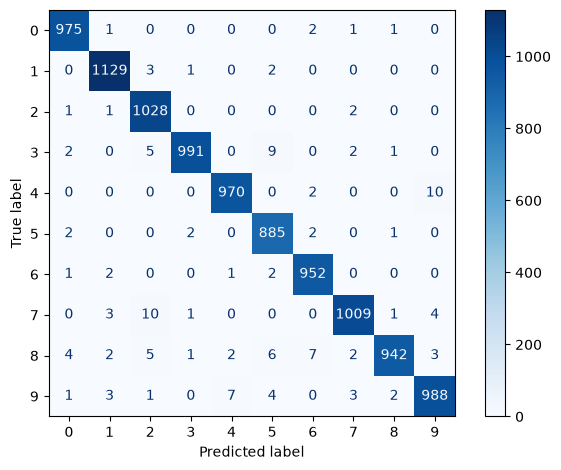

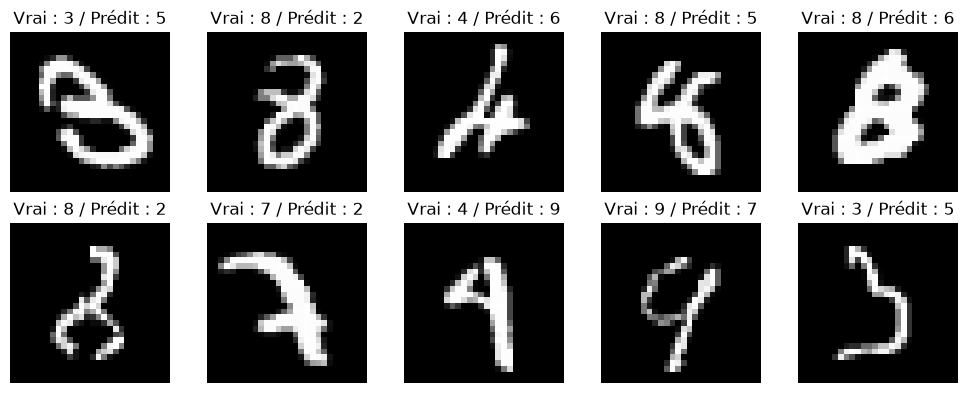

In [20]:
class MNISTClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1,16,3,padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(16,32,3,padding=1), nn.ReLU(), nn.MaxPool2d(2))
        self.classifier = nn.Sequential(nn.Flatten(), nn.Linear(32*7*7,128), nn.ReLU(), nn.Dropout(0.25), nn.Linear(128,10))
    def forward(self, x):
        return self.classifier(self.features(x))

cnn = MNISTClassifier().to(device)
with torch.no_grad():
    output = cnn(images.to(device))
assert output.shape == (images.size(0),10)
print('Sortie :', output.shape)
cnn_losses = entrainer(cnn, train_cnn, 3)
courbe(cnn_losses, '11_perte_cnn')
vrais, predits, erreurs, scores_cnn = evaluer(cnn, test_cnn)
confusion(vrais, predits, list(range(10)), '12_confusion_cnn')
afficher_erreurs(erreurs, '13_erreurs_cnn', normalise=True)
torch.save(cnn.state_dict(), 'models/mnist_cnn.pth')

In [21]:
print('Comparaison sur le même jeu de test MNIST :')
for nom in scores_mlp:
    print(f'{nom:10s} | MLP : {scores_mlp[nom]:.2%} | CNN : {scores_cnn[nom]:.2%}')

Comparaison sur le même jeu de test MNIST :
Accuracy   | MLP : 97.55% | CNN : 98.69%
Precision  | MLP : 97.53% | CNN : 98.68%
Recall     | MLP : 97.53% | CNN : 98.68%
F1         | MLP : 97.53% | CNN : 98.68%


## Conclusion
La régression prédit une valeur continue, tandis que les trois autres modèles prédisent une classe. Le CNN exploite la structure spatiale des images, contrairement au MLP qui les aplatit. La comparaison finale permet de vérifier cet avantage sur les résultats obtenus.